In [25]:
import os
os.environ.pop("PYTHONPATH", None)

import sys
sys.path = [
    p for p in sys.path
    if "/opt/software-current/" not in p
]

import regex
print("regex:", regex.__file__)

regex: /mnt/home/linpaul1/Documents/SPROUT/.venv/lib/python3.13/site-packages/regex/__init__.py


In [26]:
import pandas as pd

df = pd.read_csv("images.csv").fillna("")

In [27]:
import torch
from transformers import AutoModel, AutoProcessor
from PIL import Image
import torch.nn.functional as F

MODEL_NAME = "google/siglip2-base-patch16-224"

device = "cuda" if torch.cuda.is_available() else "cpu"

model = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()
processor = AutoProcessor.from_pretrained(MODEL_NAME)


def embed(image_path: str):
    image = Image.open(image_path).convert("RGB")
    inputs = processor(images=image, return_tensors="pt").to(device)

    with torch.inference_mode():
        output = model.get_image_features(**inputs)
        embedding = output.pooler_output
        embedding = F.normalize(embedding, p=2, dim=-1)

    return embedding.squeeze(0)

def embed_text(text: str):
    inputs = processor(text=[text],
        padding="max_length", return_tensors="pt").to(device)

    with torch.inference_mode():
        output = model.get_text_features(**inputs)
        embedding = output.pooler_output
        embedding = F.normalize(embedding, p=2, dim=-1)

    return embedding.squeeze(0)

Loading weights: 100%|██████████| 408/408 [00:00<00:00, 16535.03it/s]


In [28]:
image_embeddings = torch.stack([
    embed(str(row["image_path"])).squeeze(0).cpu()
    for _, row in df.iterrows()
]).cpu().numpy()

caption_embeddings = torch.stack([
    embed_text(str(caption)).cpu()
    for caption in df["caption"]
]).cpu().numpy()

In [31]:
TESTS = {"laptop twee": ["./images/1.jpeg", "./images/2.jpg", "./images/3.jpg"]}

IMAGE_WEIGHT = .7

for key, queries in TESTS.items():

    query_embedding = sum([embed(q).cpu().numpy() for q in queries])

    image_scores = image_embeddings @ query_embedding
    caption_scores = caption_embeddings @ query_embedding

    df[f"score_combined_{key}"] = (
        IMAGE_WEIGHT * image_scores
        + (1 - IMAGE_WEIGHT) * caption_scores
    )

# Evaluation

In [32]:
def evaluate(query, k=10):
    ranked = df.sort_values(f"score_combined_{query}", ascending=False)
    relevant = (ranked["class"] == query).to_numpy()

    n_relevant = relevant.sum()
    top_k = relevant[:k]

    precision_k = top_k.sum() / len(top_k) if len(top_k) else 0
    recall_k = top_k.sum() / n_relevant if n_relevant else 0

    precisions = [
        relevant[:i + 1].sum() / (i + 1)
        for i in range(len(relevant))
        if relevant[i]
    ]

    ap = sum(precisions) / n_relevant if n_relevant else 0

    return precision_k, recall_k, ap

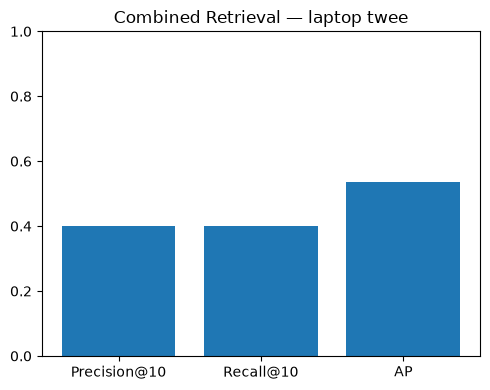

In [33]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1, len(TESTS),
    figsize=(5 * len(TESTS), 4),
    squeeze=False
)

for ax, (query, _) in zip(axes.flatten(), TESTS.items()):
    metrics = evaluate(query)

    ax.bar(
        ["Precision@10", "Recall@10", "AP"],
        metrics
    )

    ax.set_title(f"Combined Retrieval — {query}")
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

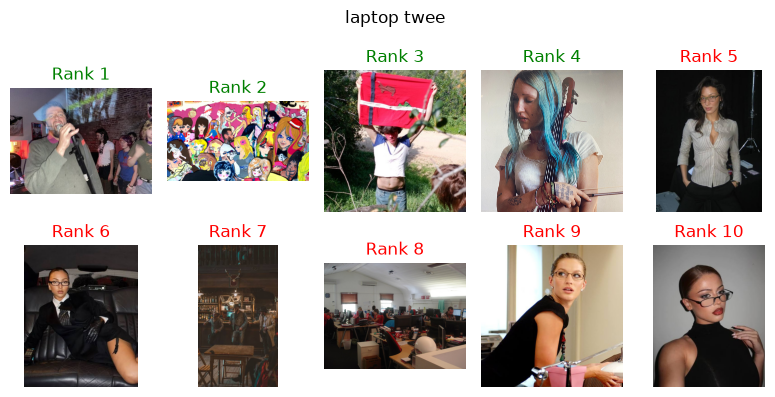

In [34]:
for query in TESTS:
    top10 = df.sort_values(
        f"score_combined_{query}",
        ascending=False
    ).head(10)

    fig, axes = plt.subplots(2, 5, figsize=(8, 4))

    for i, ax in enumerate(axes.flat):
        row = top10.iloc[i]
        ax.imshow(Image.open(row["image_path"]))
        ax.set_title(f"Rank {i + 1}", color="green" if row["class"] == query else "red")
        ax.axis("off")

    fig.suptitle(query)
    plt.tight_layout()
    plt.show()